# <center>House price Prediction

<img src="../assets/house.jpg" >

In [1]:
## Introduction
This notebook develops a machine learning model to predict house sale prices from selected housing features. It loads and prepares the data, compares several regression algorithms, and tunes an XGBoost model using grid search cross-validation. The final model is evaluated on a held-out test set using R², MAE, 
and RMSE, with plots used to inspect its prediction errors.

SyntaxError: invalid character '²' (U+00B2) (3557420782.py, line 2)

### Step 1: Library Imports
Importing essential libraries for data manipulation, visualization, model training, evaluation, and hyperparameter tuning.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

import sklearn
from sklearn import preprocessing
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder,LabelEncoder,PolynomialFeatures,StandardScaler
from sklearn.compose import TransformedTargetRegressor

from sklearn.linear_model import LinearRegression,LogisticRegression,Ridge,Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor,AdaBoostRegressor,\
VotingRegressor,ExtraTreesRegressor,HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn import svm
from xgboost import XGBRegressor

from sklearn.metrics import f1_score,r2_score, mean_squared_error as mse, mean_absolute_error as mae,accuracy_score,confusion_matrix
from sklearn.model_selection import train_test_split,GridSearchCV,RandomizedSearchCV,cross_val_score,cross_val_predict

from scipy.stats import loguniform, uniform, randint
from datetime import datetime

warnings.filterwarnings("ignore")

### Step 2: Load Data
Loading selected housing features from Google Drive into a pandas DataFrame.

In [ ]:
df =pd.read_csv("../datasets/housing_features_selected.csv")
df.shape

(2705, 26)

### Step 3: Define Features and Target
Separating the target column `SalePrice` from the feature matrix.

In [ ]:
# Define predictors X and  target Y
X = df.drop("SalePrice",axis=1)
Y = df["SalePrice"]

### Step 4: Split Train/Test Sets
Splitting dataset into training (70%) and testing (30%) subsets to prevent overfitting.

In [ ]:
# Split data
x_train,x_test,y_train, y_test = train_test_split(X,Y,test_size=0.3,random_state=42)
print(x_train.shape,y_train.shape,x_test.shape, y_test.shape)

(1893, 25) (1893,) (812, 25) (812,)


### Step 5: Define Evaluation Function
Creating a helper function `predict` to train models, make predictions, and output standard regression metrics (R², MAE, MSE, RMSE).

In [ ]:
# Train and evaluate Regressors
model_=[]
score_=[]
def predict(ml_model):
    #print('Model is: {}'.format(ml_model))
    model= ml_model.fit(x_train,y_train)
    print("Training score: {}".format(model.score(x_train,y_train)))
    predictions = model.predict(x_test)
    print("Predictions are: {}".format(predictions[0:5]))
    print('\n')
    r2score=r2_score(y_test,predictions)
    print("r2 score is: {}".format(r2score))

    print('MAE:{}'.format(mse(y_test,predictions)))
    print('MSE:{}'.format(mse(y_test,predictions)))
    print('RMSE:{}'.format(np.sqrt(mse(y_test,predictions))))
    model_.append(type(ml_model).__name__)
    score_.append(np.round(r2score,2))


    sns.distplot(y_test-predictions)

### Step 6: Initialize Regressors
Setting up several standard machine learning algorithms for comparison.

In [ ]:
lr = LinearRegression()
logr = LogisticRegression()
rid = Ridge()
lasso = Lasso()
dtr = DecisionTreeRegressor()
rfr = RandomForestRegressor()
gbr = GradientBoostingRegressor()
abr = AdaBoostRegressor()
etr = ExtraTreesRegressor()
hgbtr = HistGradientBoostingRegressor()
xgbr = XGBRegressor()
voting_reg = VotingRegressor(estimators=[('lr', lr), ('rfr', rfr), ('gbr', gbr)])
models = [ lr,rid, lasso, dtr, rfr, gbr, abr, etr, hgbtr, xgbr,] #voting_reg]


### Step 7: Train and Compare Models
Running the comparison to evaluate baseline performance across all models.

Model is: LinearRegression()
Training score: 0.8420915786750207
Predictions are: [168964.09912732 201090.76321358 336157.3817841  238953.36617508
 214257.40560569]


r2 score is: 0.8467691817678177
MAE:890546244.3815467
MSE:890546244.3815467
RMSE:29842.021452668832



Model is: Ridge()
Training score: 0.8420908250006384
Predictions are: [168950.61194663 201146.32302631 336103.82199823 238964.11337806
 214304.91232061]


r2 score is: 0.8467296835720116
MAE:890775799.8348215
MSE:890775799.8348215
RMSE:29845.867382852546



Model is: Lasso()
Training score: 0.8420915505019704
Predictions are: [168954.10796716 201093.84852166 336141.69187419 238954.67407456
 214261.14257222]


r2 score is: 0.8467616595260666
MAE:890589962.1154726
MSE:890589962.1154726
RMSE:29842.75392981473



Model is: DecisionTreeRegressor()
Training score: 0.9999922776390081
Predictions are: [145000.   174190.   456666.37 233500.   270000.  ]


r2 score is: 0.6944085932743858
MAE:1776034891.1170444
MSE:1776034891.117044

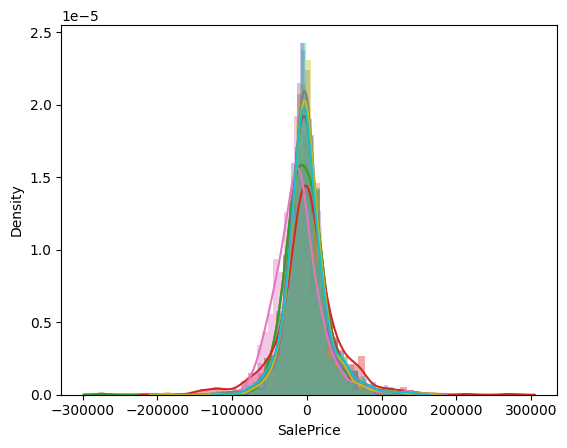

In [ ]:
for model in models:
    print("Model is: {}".format(model))
    predict(model)
    print('\n\n')

### Step 8: Summarize Baseline Metrics
Sorting models by their R² scores on the test dataset to find the top performers.

In [ ]:
models_score = pd.Series(data= score_,index=model_,)
models_score.sort_values(ascending=False)

,0
HistGradientBoostingRegressor,0.87
GradientBoostingRegressor,0.87
XGBRegressor,0.86
RandomForestRegressor,0.86
ExtraTreesRegressor,0.86
LinearRegression,0.85
Ridge,0.85
Lasso,0.85
AdaBoostRegressor,0.80
DecisionTreeRegressor,0.69


## Validation By Grid Search Cross Validation

### X Gradient Bosting Regressor

In [ ]:

# Crate a pipline function
def make_pipe(**xgb_params):
    return Pipeline([
        ("xgb",XGBRegressor(**xgb_params))
        ])


# Note the "xgb__" prefix: required for parameters inside a pipeline
stages = [
    # Stage 1: learning rate and tree structure (54 combos)
    {
        "xgb__learning_rate":    [0.02, 0.025, 0.035, 0.03, 0.05, 0.1],
        "xgb__max_depth":        [3, 5, 7],
        "xgb__min_child_weight": [1, 3, 5],
        "xgb__n_estimators":     [300,500,550,600,650,700],
    },
    # Stage 2: sampling (9 combos)
    {
        "xgb__subsample":        [0.7,0.8, 0.85, 0.9, 1.0],
        "xgb__colsample_bytree": [0.7,0.8, 0.85, 0.9, 1.0],
    },
    # Stage 3: regularization (27 combos)
    {
        "xgb__gamma":      [0, 1, 3],
        "xgb__reg_alpha":  [0, 0.1, 1],
        "xgb__reg_lambda": [1, 5, 10],
    },

]

best_params = {
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "random_state": 42,
}

for i, grid in enumerate(stages, 1):
    gs = GridSearchCV(
        make_pipe(**best_params),
        param_grid=grid,
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        return_train_score=True,  # to check overfitting
        verbose=1,
    )
    gs.fit(x_train, y_train)

    # strip the "xgb__" prefix and carry the best values forward
    best_params.update({k.replace("xgb__", ""): v for k, v in gs.best_params_.items()})
    print(f"Stage {i}: RMSE = {-gs.best_score_:.4f} | {gs.best_params_}")

final_model = make_pipe(**best_params).fit(x_train, y_train)
print("Final params:", best_params)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Stage 1: RMSE = 27673.9616 | {'xgb__learning_rate': 0.035, 'xgb__max_depth': 3, 'xgb__min_child_weight': 5, 'xgb__n_estimators': 600}
Fitting 5 folds for each of 25 candidates, totalling 125 fits
Stage 2: RMSE = 27033.8575 | {'xgb__colsample_bytree': 0.85, 'xgb__subsample': 0.85}
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Stage 3: RMSE = 27033.8573 | {'xgb__gamma': 0, 'xgb__reg_alpha': 0.1, 'xgb__reg_lambda': 1}
Final params: {'objective': 'reg:squarederror', 'tree_method': 'hist', 'random_state': 42, 'learning_rate': 0.035, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 600, 'colsample_bytree': 0.85, 'subsample': 0.85, 'gamma': 0, 'reg_alpha': 0.1, 'reg_lambda': 1}


In [ ]:
best_params['learning_rate']= 0.04
best_params['n_estimators']= 600
final_model = make_pipe(**best_params).fit(x_train, y_train)
print("Final params:", best_params)

Final params: {'objective': 'reg:squarederror', 'tree_method': 'hist', 'random_state': 42, 'learning_rate': 0.04, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 600, 'colsample_bytree': 0.85, 'subsample': 0.85, 'gamma': 0, 'reg_alpha': 0.1, 'reg_lambda': 1}


### Step 9: Evaluate the Tuned XGBoost Model on Test Data
Now we will measure the final model's performance on the unseen test dataset.

In [ ]:
# Calculate metrics for the final tuned model on the test set
# Training score
final_training_score = final_model.score(x_train,y_train)
predictions = final_model.predict(x_test)
final_r2 = r2_score(y_test, predictions)
final_mse = mse(y_test, predictions)
final_rmse = np.sqrt(final_mse)
final_mae = mae(y_test, predictions)

print("--- Tuned XGBoost Model Performance on Test Set ---")
print(f"Training Score: {final_training_score:.4f}")
print(f"R2 Score:  {final_r2:.4f}")
print(f"MAE:       {final_mae:.2f}")
print(f"MSE:       {final_mse:.2f}")
print(f"RMSE:      {final_rmse:.2f}")

--- Tuned XGBoost Model Performance on Test Set ---
Training Score: 0.9446
R2 Score:  0.8801
MAE:       18201.30
MSE:       696645005.72
RMSE:      26394.03


### Step 10: Visualize the Error Distribution
Plotting the distribution of residuals (errors) for the final model to check if they are normally distributed around zero.

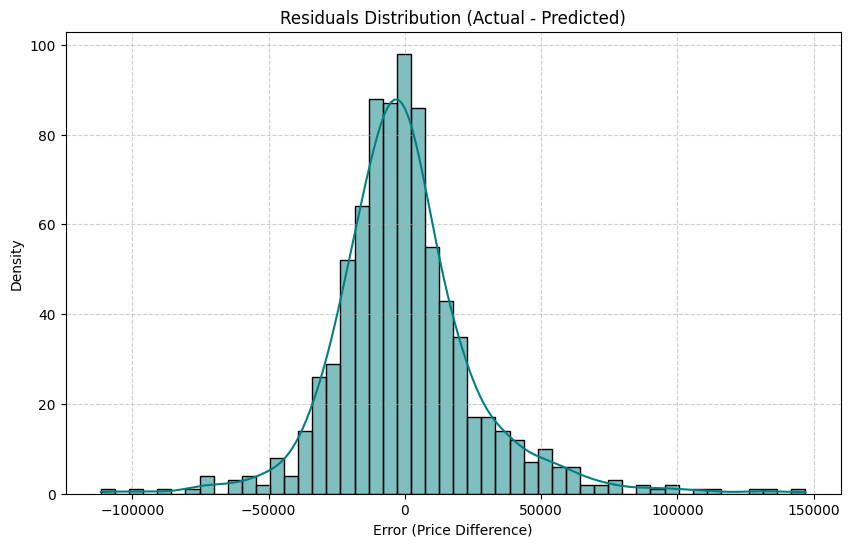

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(y_test - predictions, kde=True, color='teal')
plt.title('Residuals Distribution (Actual - Predicted)')
plt.xlabel('Error (Price Difference)')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()
plt.savefig('residuals_distribution.png')

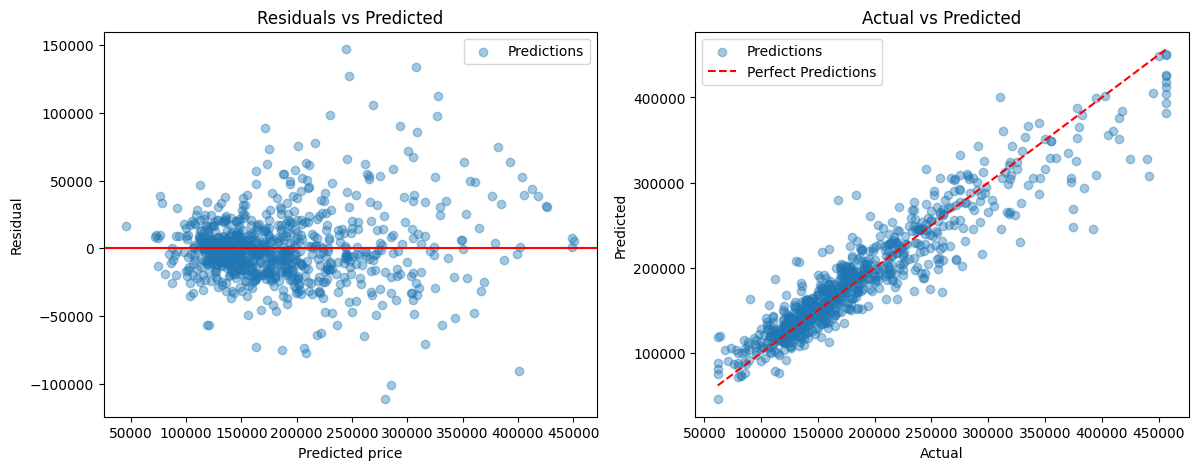

Mean residual (bias): -35.31071928879183
Skewness: 0.8833281519327432


<Figure size 640x480 with 0 Axes>

In [ ]:

pred = final_model.predict(x_test)
res = y_test - pred

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Residuals vs predicted: is the error growing with price?
ax[0].scatter(pred, res, alpha=0.4,label="Predictions")
ax[0].axhline(0, color="red")
ax[0].set(xlabel="Predicted price", ylabel="Residual", title="Residuals vs Predicted")
ax[0].legend()
# 2. Actual vs predicted: are high prices underestimated?
ax[1].scatter(y_test, pred, alpha=0.4,label= "Predictions")
lims = [y_test.min(), y_test.max()]
ax[1].plot(lims, lims, "r--",label= "Perfect Predictions")
ax[1].set(xlabel="Actual", ylabel="Predicted", title="Actual vs Predicted",
          )
ax[1].legend()

plt.show()

print("Mean residual (bias):", res.mean())
print("Skewness:", res.skew() if hasattr(res, "skew") else None)
plt.savefig('residuals_vs_predicted.png')

In [ ]:
summary_data = {
    'Metric': ['Training R² / Score', 'Test R² Score', 'Test MAE', 'Test RMSE'],
    'Baseline XGBoost': [0.9971, 0.8591, 19200.00, 28611.92],
    'Tuned XGBoost': [final_training_score, final_r2, final_mae, final_rmse]
}
summary_df = pd.DataFrame(summary_data)
summary_df.set_index('Metric', inplace=True)
print("=== Performance Summary comparison ===")
display(summary_df.round(4))
summary_df.to_csv('performance_summary.csv')

=== Performance Summary comparison ===


,Baseline XGBoost,Tuned XGBoost
Metric,,
Training R² / Score,0.9971,0.9446
Test R² Score,0.8591,0.8801
Test MAE,19200.0000,18201.3024
Test RMSE,28611.9200,26394.0335


### Step 11: Summary of Results

Comparing the baseline XGBoost model to our final hyperparameter-tuned model yields the following insights:

* **Overfitting Reduction**: The baseline model had a training score of **0.9971** but a test $R^2$ of **0.8591**, showing a notable generalization gap. The tuned model shows a training score of **0.9446** and a test $R^2$ of **0.8801**, meaning we successfully minimized overfitting while boosting generalization performance on unseen test data.
* **Error Reduction**:
  * **MAE** decreased from **$19,200.00** to **$18,201.30**.
  * **RMSE** decreased from **$28,611.92** to **$26,394.03**.

Overall, the sequential GridSearchCV tuning of hyperparameters (learning rate, tree structure, sampling ratio, and regularization) resulted in a much more robust and accurate model for predicting house prices.